In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

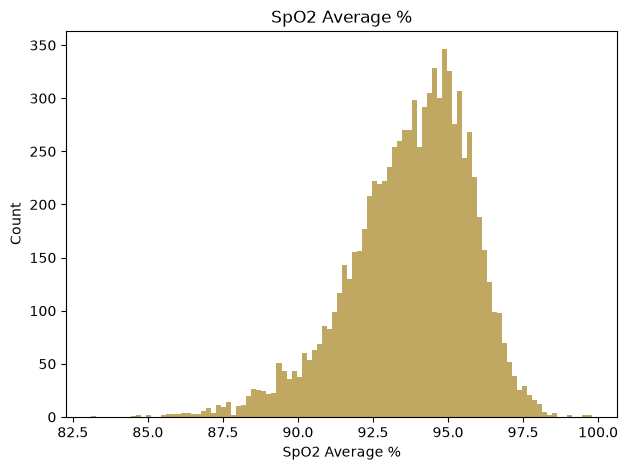

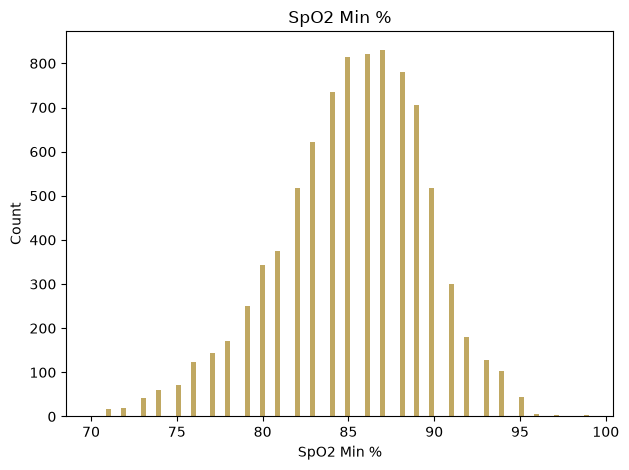

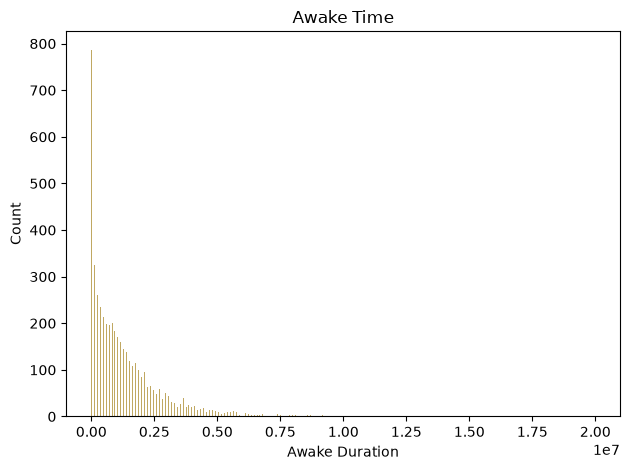

In [3]:
spo2_cleaned = pd.read_csv("../../data/clean/dataset_with_spo2_cleaned.csv")


fig, ax = plt.subplots()
ax.hist(spo2_cleaned["spo2_mean"], bins=100, color="#A6841F", alpha=0.7)
ax.set_title("SpO2 Average %")
ax.set_xlabel("SpO2 Average %")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
plt.close()

fig, ax = plt.subplots()
ax.hist(spo2_cleaned["spo2_min"], bins=100, color="#A6841F", alpha=0.7)
ax.set_title("SpO2 Min %")
ax.set_xlabel("SpO2 Min %")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
plt.close()

fig, ax = plt.subplots()
ax.hist(spo2_cleaned["awakeDurationInMs"], bins=1000, color="#A6841F", alpha=0.7)
ax.set_title("Awake Time")
ax.set_xlabel("Awake Duration")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
plt.close()

In [5]:
dataset_without_spo2 = pd.read_csv("../data/clean/dataset_without_spo2_cleaned.csv")

dataset_without_spo2["hrv_personal_average"] = dataset_without_spo2.groupby("participant_id")["lastNightAvg"].transform("mean")
dataset_without_spo2["hrv_ratio"] = dataset_without_spo2["lastNightAvg"]/dataset_without_spo2["hrv_personal_average"]
dataset_without_spo2.head().T


,0,1,2,3,4
participant_id,P1,P1,P1,P1,P1
calendarDate,2025-07-13,2025-08-18,2025-08-19,2025-08-20,2025-08-21
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,28620000.0,28500000.0,26520000.0,25500000.0,23460000.0
deepSleepDurationInMs,3480000.0,5160000.0,2160000.0,4620000.0,2820000.0
lightSleepDurationInMs,20160000.0,20100000.0,20040000.0,16980000.0,19620000.0
remSleepInMs,4980000.0,3240000.0,4320000.0,3900000.0,1020000.0
awakeDurationInMs,360000.0,780000.0,180000.0,0.0,900000.0
overallSleepScore,79.0,79.0,79.0,80.0,48.0
breathsPerMinute_mean,19.0785,19.163504,18.843708,17.915741,18.371798


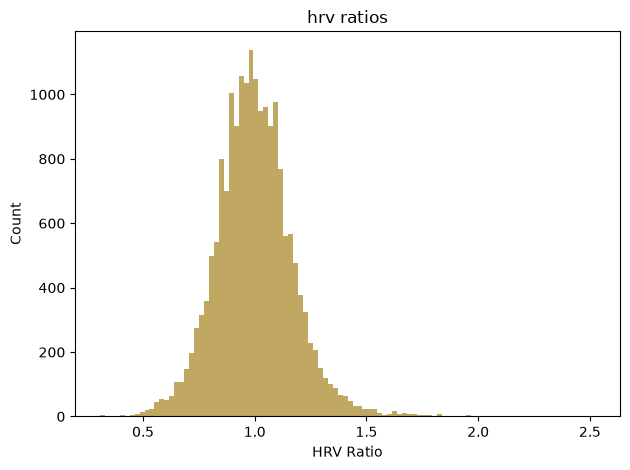

In [10]:
fig, ax = plt.subplots()
ax.hist(dataset_without_spo2["hrv_ratio"], bins=100, color="#A6841F", alpha=0.7)
ax.set_title("hrv ratios")
ax.set_xlabel("HRV Ratio")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
plt.close()

In [15]:
print(f"Number of nights 20% below individual normal: {(dataset_without_spo2["hrv_ratio"]<=.8).sum()}")
print(f"Number of nights 30% below individual normal: {(dataset_without_spo2["hrv_ratio"]<=.7).sum()}")
print(f"Number of nights 40% below individual normal: {(dataset_without_spo2["hrv_ratio"]<=.6).sum()}")

Number of nights 20% below individual normal: 1920
Number of nights 30% below individual normal: 628
Number of nights 40% below individual normal: 196


In [19]:
dataset_with_spo2 = pd.read_csv("../data/clean/dataset_with_spo2_cleaned.csv")

dataset_with_spo2["awake_share"] = dataset_with_spo2["awakeDurationInMs"]/(dataset_with_spo2["awakeDurationInMs"]+dataset_with_spo2["durationInMs"])
dataset_with_spo2.head().T

,0,1,2,3,4
participant_id,P2,P2,P2,P2,P2
calendarDate,2026-05-09,2026-05-10,2026-05-11,2026-05-12,2026-05-16
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0
lightSleepDurationInMs,11700000.0,9660000.0,15240000.0,13140000.0,10980000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0
breathsPerMinute_mean,16.035746,16.368302,16.775543,16.971122,17.72412


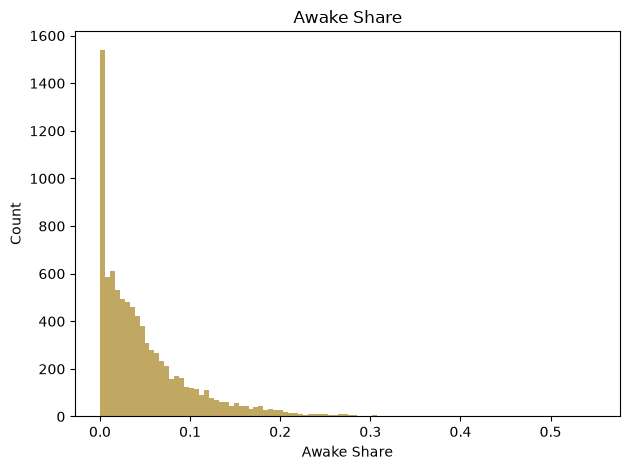

In [23]:
fig, ax = plt.subplots()
ax.hist(dataset_with_spo2["awake_share"], bins=100, color="#A6841F", alpha=0.7)
ax.set_title("Awake Share")
ax.set_xlabel("Awake Share")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
plt.close()

In [ ]:
dataset_with_spo2["spo2_z"] = (dataset_with_spo2["spo2_mean"]-dataset_with_spo2["spo2_mean"].mean())/dataset_with_spo2["spo2_mean"].std()
dataset_with_spo2["awake_z"] = (dataset_with_spo2["awake_share"]-dataset_with_spo2["awake_share"].mean())/dataset_with_spo2["awake_share"].std()
print(f"Number of nights where spo2 is at or below -1 z: {(dataset_with_spo2["spo2_z"]<=-1).sum()}")
print(f"Number of nights where awake share is at or above 1 z: {(dataset_with_spo2["awake_z"]>=1).sum()}")
print(f"Number of nights where spo2 is at or below -1 and awake share is at or above 1 z: {((dataset_with_spo2['spo2_z']<=-1) & (dataset_with_spo2['awake_z']>=1)).sum()}")


Number of nights where spo2 is at or below -1 z: 1314
Number of nights where awake share is at or above 1 z: 1117
Number of nights where spo2 is at or below -1 and awake share is at or above 1 z: 177


In [33]:
overlap = (dataset_with_spo2['spo2_z'] <= -1) & (dataset_with_spo2['awake_z'] >= 1)
print(dataset_with_spo2[overlap]['participant_id'].nunique())
print(dataset_with_spo2[overlap]['participant_id'].value_counts().head(10))

21
participant_id
P20    72
P68    26
P6     13
P50    10
P24     8
P30     8
P43     8
P22     7
P90     6
P19     4
Name: count, dtype: int64
